# 03 — PySR Seed-Stability Study

This notebook tests whether the targeted low-complexity PySR search consistently recovers the paper-like exponential relation

$$
\frac{D_H(z)}{r_d}=A\exp(Bz).
$$

It repeats the same search over multiple random seeds and both covariance choices. This is a stability experiment, not a new choice of the preferred physical model.

## 1. Imports and software versions

In [29]:
from pathlib import Path
import importlib.metadata as metadata
import json
import platform

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sympy as sp
from pysr import PySRRegressor, jl

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.float_format", lambda value: f"{value:.6f}")

SOFTWARE_VERSIONS = {
    "python": platform.python_version(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "sympy": sp.__version__,
    "pysr": metadata.version("pysr"),
    "julia": str(jl.seval("string(VERSION)")),
}
display(pd.Series(SOFTWARE_VERSIONS, name="version").to_frame())

,version
python,3.13.11
numpy,2.5.2
pandas,2.3.3
sympy,1.14.0
pysr,1.5.9
julia,1.12.7


## 2. Load the validated DESI dataset

The data are read from Notebook 01. The public covariance and the diagonal covariance constructed from the rounded uncertainties in the paper are retained as separate configurations.

In [30]:
def find_project_root(start: Path) -> Path:
    """Return the nearest parent containing the Notebook 01 result."""
    for candidate in (start, *start.parents):
        expected = (
            candidate
            / "results"
            / "01_desi_data_check"
            / "desi_dr2_dh_over_rd.npz"
        )
        if expected.is_file():
            return candidate
    raise FileNotFoundError(
        "Could not locate the Notebook 01 result. Run Notebook 01 first."
    )


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
INPUT_FILE = (
    PROJECT_ROOT
    / "results"
    / "01_desi_data_check"
    / "desi_dr2_dh_over_rd.npz"
)

with np.load(INPUT_FILE) as data:
    z = data["z"].astype(float)
    y = data["y"].astype(float)
    public_covariance = data["covariance"].astype(float)
    public_sigma = data["sigma"].astype(float)
    tracers = data["tracers"].astype(str)

X = z.reshape(-1, 1)
N_DATA = len(z)
PAPER_TABLE_SIGMA = np.array([0.425, 0.330, 0.193, 0.221, 0.516, 0.101])
paper_table_covariance = np.diag(PAPER_TABLE_SIGMA**2)

COVARIANCE_CONFIGS = {
    "public_full": public_covariance,
    "paper_table": paper_table_covariance,
}

assert N_DATA == 6
assert public_covariance.shape == (N_DATA, N_DATA)
assert np.allclose(public_covariance, public_covariance.T)
assert np.linalg.eigvalsh(public_covariance).min() > 0.0

display(
    pd.DataFrame(
        {"tracer": tracers, "z": z, "DH_over_rd": y, "sigma": public_sigma}
    )
)
print(f"Input file: {INPUT_FILE}")

,tracer,z,DH_over_rd,sigma
0,LRG1,0.510000,21.862947,0.428868
1,LRG2,0.706000,19.455349,0.333870
2,LRG3+ELG1,0.934000,17.641495,0.201043
3,ELG2,1.321000,14.176022,0.224551
4,QSO,1.484000,12.817000,0.518012
5,Ly-alpha,2.330000,8.631546,0.101062


Input file: /Users/kemingliu/Desktop/Dark Energy/results/01_desi_data_check/desi_dr2_dh_over_rd.npz


## 3. Stability-test configuration

The pilot contains five seeds. The final set contains 20 seeds: seed `42` plus 19 consecutive seeds beginning at `202502`. Both modes use exactly the same PySR search settings.

In [31]:
# Change this to True when you are ready to launch the searches.
RUN_PYSR = True
RUN_MODE = "final"  # Use "pilot" first, then "final".
IMPORT_COMPATIBLE_HISTORY = True

PILOT_SEEDS = (42, 202502, 202503, 202504, 202505)
FINAL_SEEDS = (42, *tuple(range(202502, 202601)))
SEED_SETS = {"pilot": PILOT_SEEDS, "final": FINAL_SEEDS}
if RUN_MODE not in SEED_SETS:
    raise ValueError('RUN_MODE must be either "pilot" or "final".')
TARGETED_SEEDS = SEED_SETS[RUN_MODE]
assert len(set(TARGETED_SEEDS)) == len(TARGETED_SEEDS)

EXPERIMENT_DATE = "20260906"
MAXSIZE = 7
NITERATIONS = 120
EXPERIMENT_ID = (
    f"targeted_maxsize{MAXSIZE}_{len(TARGETED_SEEDS)}seeds_"
    f"{RUN_MODE}_{EXPERIMENT_DATE}"
)
RESULTS_DIR = PROJECT_ROOT / "results" / "03_desi_pysr_seed_stability"
EXPERIMENT_DIR = RESULTS_DIR / EXPERIMENT_ID
RUNS_DIR = EXPERIMENT_DIR / "runs"
COMPLETED_DIR = EXPERIMENT_DIR / "completed"
CANDIDATES_DIR = EXPERIMENT_DIR / "candidates"
FIGURES_DIR = EXPERIMENT_DIR / "figures"
SUMMARY_FILE = EXPERIMENT_DIR / "summary.csv"
CLASSIFIED_FILE = EXPERIMENT_DIR / "classified_summary.csv"
CONFIGURATION_FILE = EXPERIMENT_DIR / "configuration.json"

for directory in (RUNS_DIR, COMPLETED_DIR, CANDIDATES_DIR, FIGURES_DIR):
    directory.mkdir(parents=True, exist_ok=True)

PYSR_SETTINGS = {
    "model_selection": "best",
    "binary_operators": ["+", "-", "*", "/", "^"],
    "unary_operators": ["log", "sqrt", "exp", "square", "cube"],
    "constraints": {"^": (-1, 1)},
    "niterations": NITERATIONS,
    "populations": 8,
    "population_size": 30,
    "maxsize": MAXSIZE,
    "ncycles_per_iteration": 300,
    "precision": 64,
    "parallelism": "serial",
    "deterministic": True,
    "progress": False,
    "verbosity": 0,
}

configuration = {
    "experiment_id": EXPERIMENT_ID,
    "run_mode": RUN_MODE,
    "seeds": list(TARGETED_SEEDS),
    "covariances": list(COVARIANCE_CONFIGS),
    "number_of_expected_runs": len(TARGETED_SEEDS) * len(COVARIANCE_CONFIGS),
    "settings": PYSR_SETTINGS,
    "software_versions": SOFTWARE_VERSIONS,
}
with CONFIGURATION_FILE.open("w", encoding="utf-8") as stream:
    json.dump(configuration, stream, indent=2)

print(f"Experiment: {EXPERIMENT_ID}")
print(f"Seeds: {TARGETED_SEEDS}")
print(f"Expected PySR runs: {configuration['number_of_expected_runs']}")
print(f"Results directory: {EXPERIMENT_DIR}")

Experiment: targeted_maxsize7_100seeds_final_20260906
Seeds: (42, 202502, 202503, 202504, 202505, 202506, 202507, 202508, 202509, 202510, 202511, 202512, 202513, 202514, 202515, 202516, 202517, 202518, 202519, 202520, 202521, 202522, 202523, 202524, 202525, 202526, 202527, 202528, 202529, 202530, 202531, 202532, 202533, 202534, 202535, 202536, 202537, 202538, 202539, 202540, 202541, 202542, 202543, 202544, 202545, 202546, 202547, 202548, 202549, 202550, 202551, 202552, 202553, 202554, 202555, 202556, 202557, 202558, 202559, 202560, 202561, 202562, 202563, 202564, 202565, 202566, 202567, 202568, 202569, 202570, 202571, 202572, 202573, 202574, 202575, 202576, 202577, 202578, 202579, 202580, 202581, 202582, 202583, 202584, 202585, 202586, 202587, 202588, 202589, 202590, 202591, 202592, 202593, 202594, 202595, 202596, 202597, 202598, 202599, 202600)
Expected PySR runs: 200
Results directory: /Users/kemingliu/Desktop/Dark Energy/results/03_desi_pysr_seed_stability/targeted_maxsize7_100seeds

## 4. Full covariance-weighted loss

For residual vector $r$, every search minimizes

$$
\mathcal{L}=\frac{1}{N}r^{\mathsf T}C^{-1}r.
$$

In [32]:
def chi_square(observed, predicted, covariance):
    """Return r.T @ C^-1 @ r without explicitly forming C^-1."""
    residual = np.asarray(predicted) - np.asarray(observed)
    return float(residual @ np.linalg.solve(covariance, residual))


def make_julia_covariance_loss(covariance):
    """Create the Julia objective used by PySR for one covariance matrix."""
    inverse_covariance = np.linalg.inv(covariance)
    matrix_rows = [
        " ".join(f"{value:.17g}" for value in row)
        for row in inverse_covariance
    ]
    matrix_literal = ";\n        ".join(matrix_rows)
    return f"""
function covariance_loss(tree, dataset::Dataset{{T,L}}, options)::L where {{T,L}}
    prediction, flag = eval_tree_array(tree, dataset.X, options)
    if !flag || any(value -> !isfinite(value), prediction)
        return L(Inf)
    end
    residual = prediction .- dataset.y
    inverse_covariance = T[
        {matrix_literal}
    ]
    return L(sum(residual .* (inverse_covariance * residual)) / dataset.n)
end
"""


for covariance_name, covariance in COVARIANCE_CONFIGS.items():
    assert "inverse_covariance" in make_julia_covariance_loss(covariance)
    print(f"Prepared covariance-weighted objective: {covariance_name}")

Prepared covariance-weighted objective: public_full
Prepared covariance-weighted objective: paper_table


## 5. Import compatible historical runs

Notebook 02 already produced targeted runs for seeds `42` and `202502`. This cell imports their summary rows into the current experiment, while leaving the original files unchanged. In final mode it also imports all compatible completed pilot runs.

In [33]:
NOTEBOOK_02_RESULTS = PROJECT_ROOT / "results" / "02_desi_pysr"
PILOT_EXPERIMENT_DIRECTORY = (
    RESULTS_DIR / f"targeted_maxsize{MAXSIZE}_{len(PILOT_SEEDS)}seeds_pilot_{EXPERIMENT_DATE}"
)
HISTORICAL_EXPERIMENTS = (
    NOTEBOOK_02_RESULTS / "targeted_maxsize7_seed42_20260906",
    NOTEBOOK_02_RESULTS / "targeted_maxsize7_seed202502_20260906",
    PILOT_EXPERIMENT_DIRECTORY,
)
COMPATIBILITY_KEYS = (
    "model_selection",
    "binary_operators",
    "unary_operators",
    "niterations",
    "populations",
    "population_size",
    "maxsize",
    "ncycles_per_iteration",
    "precision",
    "parallelism",
    "deterministic",
)

imported_rows = 0
if IMPORT_COMPATIBLE_HISTORY:
    for historical_directory in HISTORICAL_EXPERIMENTS:
        historical_summary_file = historical_directory / "summary.csv"
        historical_configuration_file = historical_directory / "configuration.json"
        if not historical_summary_file.is_file() or not historical_configuration_file.is_file():
            continue

        historical = pd.read_csv(historical_summary_file)
        with historical_configuration_file.open(encoding="utf-8") as stream:
            historical_configuration = json.load(stream)

        historical_settings = historical_configuration.get("settings", {})
        settings_match = all(
            historical_settings.get(key) == PYSR_SETTINGS.get(key)
            for key in COMPATIBILITY_KEYS
        )
        if not settings_match:
            print(f"Skipped incompatible history: {historical_directory.name}")
            continue

        for _, row in historical.iterrows():
            seed = int(row["seed"])
            if seed not in TARGETED_SEEDS:
                continue
            run_id = f"{row['covariance']}_seed_{seed}_maxsize_{MAXSIZE}"
            destination = COMPLETED_DIR / f"{run_id}.csv"
            if destination.is_file():
                continue
            imported = row.to_dict()
            imported["run_id"] = run_id
            imported["result_source"] = f"imported:{historical_directory.name}"
            pd.DataFrame([imported]).to_csv(destination, index=False)
            imported_rows += 1

print(f"Imported historical result rows: {imported_rows}")

Imported historical result rows: 10


## 6. Run or resume the multi-seed search

Each seed is run once for each covariance. A one-row CSV is written immediately after every successful run, so completed work survives an interruption or kernel restart.

In [34]:
def completed_result_file(covariance_name, seed):
    run_id = f"{covariance_name}_seed_{seed}_maxsize_{MAXSIZE}"
    return run_id, COMPLETED_DIR / f"{run_id}.csv"


for covariance_name, covariance in COVARIANCE_CONFIGS.items():
    for seed in TARGETED_SEEDS:
        run_id, result_file = completed_result_file(covariance_name, seed)
        if result_file.is_file():
            print(f"Skipping completed run: {run_id}")
            continue
        if not RUN_PYSR:
            continue

        print(f"Running PySR: covariance={covariance_name}, seed={seed}")
        model = PySRRegressor(
            **PYSR_SETTINGS,
            random_state=seed,
            loss_function=make_julia_covariance_loss(covariance),
            output_directory=str(RUNS_DIR),
            run_id=run_id,
        )
        model.fit(X, y, variable_names=["z"])

        selected = model.get_best()
        selected_index = int(selected.name)
        prediction = np.asarray(
            model.predict(X, index=selected_index), dtype=float
        ).reshape(-1)
        selected_chi2 = chi_square(y, prediction, covariance)

        result_row = {
            "covariance": covariance_name,
            "seed": seed,
            "run_id": run_id,
            "maxsize": MAXSIZE,
            "complexity": int(selected["complexity"]),
            "pysr_loss": float(selected["loss"]),
            "python_chi2": selected_chi2,
            "python_loss": selected_chi2 / N_DATA,
            "equation": str(selected["equation"]),
            "sympy_expression": str(selected["sympy_format"]),
            "result_source": "new_run",
        }
        pd.DataFrame([result_row]).to_csv(result_file, index=False)

        candidate_columns = [
            column
            for column in ("complexity", "loss", "score", "equation", "sympy_format")
            if column in model.equations_.columns
        ]
        candidates = model.equations_[candidate_columns].copy()
        candidates["covariance"] = covariance_name
        candidates["seed"] = seed
        candidates["selected_by_best"] = candidates.index == selected_index
        candidates.to_csv(CANDIDATES_DIR / f"{run_id}.csv", index=False)
        print(f"Selected: {selected['sympy_format']}")

completed_files = sorted(COMPLETED_DIR.glob("*.csv"))
if completed_files:
    stability_summary = pd.concat(
        [pd.read_csv(path) for path in completed_files], ignore_index=True
    )
    stability_summary = (
        stability_summary
        .sort_values(["covariance", "seed"])
        .drop_duplicates(["covariance", "seed"], keep="last")
        .reset_index(drop=True)
    )
    stability_summary.to_csv(SUMMARY_FILE, index=False)
else:
    stability_summary = pd.DataFrame()

expected_runs = len(TARGETED_SEEDS) * len(COVARIANCE_CONFIGS)
print(f"Completed runs: {len(stability_summary)}/{expected_runs}")
if stability_summary.empty:
    print("No results yet. Set RUN_PYSR = True and rerun this cell.")
else:
    display(stability_summary)
    print(f"Saved summary: {SUMMARY_FILE}")

Skipping completed run: public_full_seed_42_maxsize_7
Skipping completed run: public_full_seed_202502_maxsize_7
Skipping completed run: public_full_seed_202503_maxsize_7
Skipping completed run: public_full_seed_202504_maxsize_7
Skipping completed run: public_full_seed_202505_maxsize_7
Running PySR: covariance=public_full, seed=202506
Selected: 27.80993373377982*sqrt(exp(-z))
Running PySR: covariance=public_full, seed=202507
Selected: 27.80993373951002*sqrt(exp(-z))
Running PySR: covariance=public_full, seed=202508
Selected: 27.80993373954622*sqrt(exp(-z))
Running PySR: covariance=public_full, seed=202509
Selected: 0.6015206744295819**z/0.03556159893534236
Running PySR: covariance=public_full, seed=202510
Selected: 27.80993373954893*sqrt(exp(-z))
Running PySR: covariance=public_full, seed=202511
Selected: 27.80993373441376*sqrt(exp(-z))
Running PySR: covariance=public_full, seed=202512
Selected: 27.80993373377982*sqrt(exp(-z))
Running PySR: covariance=public_full, seed=202513
Selected: 

,covariance,seed,run_id,maxsize,complexity,pysr_loss,python_chi2,python_loss,equation,sympy_expression,result_source
0,paper_table,42,paper_table_seed_42_maxsize_7,7,7,0.385125,2.310748,0.385125,45.641250344062 / (sqrt(cube(z)) + 1.713195404...,45.641250344062/(sqrt(z**3) + 1.7131954048188751),imported:targeted_maxsize7_seed42_20260906
1,paper_table,202502,paper_table_seed_202502_maxsize_7,7,6,0.421558,2.529349,0.421558,exp((z * -0.5084602991924945) + 3.336827905336...,exp(3.3368279053368424 + z*(-0.5084602991924945)),imported:targeted_maxsize7_seed202502_20260906
2,paper_table,202503,paper_table_seed_202503_maxsize_7,7,5,0.421558,2.529349,0.421558,(0.6014208740880829 ^ z) * 28.129754818816604,0.6014208740880829**z*28.129754818816604,imported:targeted_maxsize7_5seeds_pilot_20260906
3,paper_table,202504,paper_table_seed_202504_maxsize_7,7,5,0.561097,3.366583,0.561097,sqrt(773.7422716632847 / exp(z)),27.81622317395524*sqrt(exp(-z)),imported:targeted_maxsize7_5seeds_pilot_20260906
4,paper_table,202505,paper_table_seed_202505_maxsize_7,7,6,0.421565,2.529391,0.421565,exp((z * -0.5084789656882723) - -3.33681500639...,exp(z*(-0.5084789656882723) - 1*(-3.3368150063...,imported:targeted_maxsize7_5seeds_pilot_20260906
...,...,...,...,...,...,...,...,...,...,...,...
195,public_full,202596,public_full_seed_202596_maxsize_7,7,6,0.407375,2.444247,0.407375,exp((z * -0.5082944227942395) + 3.336488976172...,exp(3.3364889761729732 + z*(-0.5082944227942395)),new_run
196,public_full,202597,public_full_seed_202597_maxsize_7,7,5,0.539484,3.236906,0.539484,sqrt(773.3924145976919 / exp(z)),27.80993373954156*sqrt(exp(-z)),new_run
197,public_full,202598,public_full_seed_202598_maxsize_7,7,6,0.407375,2.444247,0.407375,exp((z * -0.508294422910234) + 3.3364889760849...,exp(3.3364889760849485 + z*(-0.508294422910234)),new_run
198,public_full,202599,public_full_seed_202599_maxsize_7,7,5,0.407375,2.444247,0.407375,28.12022244028174 / (1.6624533341806633 ^ z),28.12022244028174/(1.6624533341806633**z),new_run


Saved summary: /Users/kemingliu/Desktop/Dark Energy/results/03_desi_pysr_seed_stability/targeted_maxsize7_100seeds_final_20260906/summary.csv


## 7. Classify the selected equations

A result is labelled `paper_like_exponential` when its logarithmic derivative is constant, meaning it is algebraically equivalent to $A\exp(Bz)$. This recognizes equivalent forms such as `exp(z / c + d)`.

In [35]:
z_symbol = sp.Symbol("z", real=True)


def classify_expression(expression_text):
    """Assign a broad structural class to a saved SymPy expression."""
    try:
        expression = sp.sympify(expression_text, locals={"z": z_symbol})
        if expression.has(sp.exp):
            logarithmic_derivative = sp.simplify(
                sp.diff(expression, z_symbol) / expression
            )
            if not logarithmic_derivative.has(z_symbol):
                return "paper_like_exponential"
            return "contains_exponential"
        try:
            degree = sp.Poly(expression, z_symbol).degree()
            if degree == 2:
                return "quadratic"
            if degree is not None:
                return "polynomial"
        except sp.PolynomialError:
            pass
        has_fractional_power = any(
            node.is_Pow and node.exp.is_Rational and node.exp.q != 1
            for node in sp.preorder_traversal(expression)
        )
        if has_fractional_power or sp.denom(expression) != 1:
            return "rational_or_root"
        return "other"
    except Exception:
        return "unparsed"


def extract_exponential_parameters(expression_text):
    """Return A and B when the expression is equivalent to A * exp(B z)."""
    try:
        expression = sp.sympify(expression_text, locals={"z": z_symbol})
        slope = sp.simplify(sp.diff(expression, z_symbol) / expression)
        if expression.has(sp.exp) and not slope.has(z_symbol):
            # For A*exp(Bz), A is the expression evaluated at z=0.
            # This also handles equivalent forms such as sqrt(exp(-z)).
            amplitude = expression.subs(z_symbol, 0)
            return float(sp.N(amplitude)), float(sp.N(slope))
    except Exception:
        pass
    return np.nan, np.nan


if stability_summary.empty:
    classified_summary = pd.DataFrame()
    print("Run Section 6 before classifying equations.")
else:
    classified_summary = stability_summary.copy()
    classified_summary["model_class"] = classified_summary["sympy_expression"].map(
        classify_expression
    )
    parameters = classified_summary["sympy_expression"].map(
        extract_exponential_parameters
    )
    classified_summary[["exponential_A", "exponential_B"]] = pd.DataFrame(
        parameters.tolist(), index=classified_summary.index
    )
    classified_summary.to_csv(CLASSIFIED_FILE, index=False)
    display(classified_summary)
    print(f"Saved classified results: {CLASSIFIED_FILE}")

,covariance,seed,run_id,maxsize,complexity,pysr_loss,python_chi2,python_loss,equation,sympy_expression,result_source,model_class,exponential_A,exponential_B
0,paper_table,42,paper_table_seed_42_maxsize_7,7,7,0.385125,2.310748,0.385125,45.641250344062 / (sqrt(cube(z)) + 1.713195404...,45.641250344062/(sqrt(z**3) + 1.7131954048188751),imported:targeted_maxsize7_seed42_20260906,rational_or_root,NaN,NaN
1,paper_table,202502,paper_table_seed_202502_maxsize_7,7,6,0.421558,2.529349,0.421558,exp((z * -0.5084602991924945) + 3.336827905336...,exp(3.3368279053368424 + z*(-0.5084602991924945)),imported:targeted_maxsize7_seed202502_20260906,paper_like_exponential,28.129755,-0.508460
2,paper_table,202503,paper_table_seed_202503_maxsize_7,7,5,0.421558,2.529349,0.421558,(0.6014208740880829 ^ z) * 28.129754818816604,0.6014208740880829**z*28.129754818816604,imported:targeted_maxsize7_5seeds_pilot_20260906,other,NaN,NaN
3,paper_table,202504,paper_table_seed_202504_maxsize_7,7,5,0.561097,3.366583,0.561097,sqrt(773.7422716632847 / exp(z)),27.81622317395524*sqrt(exp(-z)),imported:targeted_maxsize7_5seeds_pilot_20260906,paper_like_exponential,27.816223,-0.500000
4,paper_table,202505,paper_table_seed_202505_maxsize_7,7,6,0.421565,2.529391,0.421565,exp((z * -0.5084789656882723) - -3.33681500639...,exp(z*(-0.5084789656882723) - 1*(-3.3368150063...,imported:targeted_maxsize7_5seeds_pilot_20260906,paper_like_exponential,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,public_full,202596,public_full_seed_202596_maxsize_7,7,6,0.407375,2.444247,0.407375,exp((z * -0.5082944227942395) + 3.336488976172...,exp(3.3364889761729732 + z*(-0.5082944227942395)),new_run,paper_like_exponential,28.120222,-0.508294
196,public_full,202597,public_full_seed_202597_maxsize_7,7,5,0.539484,3.236906,0.539484,sqrt(773.3924145976919 / exp(z)),27.80993373954156*sqrt(exp(-z)),new_run,paper_like_exponential,27.809934,-0.500000
197,public_full,202598,public_full_seed_202598_maxsize_7,7,6,0.407375,2.444247,0.407375,exp((z * -0.508294422910234) + 3.3364889760849...,exp(3.3364889760849485 + z*(-0.508294422910234)),new_run,paper_like_exponential,28.120222,-0.508294
198,public_full,202599,public_full_seed_202599_maxsize_7,7,5,0.407375,2.444247,0.407375,28.12022244028174 / (1.6624533341806633 ^ z),28.12022244028174/(1.6624533341806633**z),new_run,rational_or_root,NaN,NaN


Saved classified results: /Users/kemingliu/Desktop/Dark Energy/results/03_desi_pysr_seed_stability/targeted_maxsize7_100seeds_final_20260906/classified_summary.csv


## 8. Calculate stability statistics

The main quantity is the exponential hit rate for each covariance. A Wilson 95% interval is reported because the number of seeds is finite.

In [36]:
def wilson_interval(successes, trials, z_value=1.96):
    """Return the Wilson binomial confidence interval."""
    if trials == 0:
        return np.nan, np.nan
    proportion = successes / trials
    denominator = 1.0 + z_value**2 / trials
    centre = (proportion + z_value**2 / (2.0 * trials)) / denominator
    half_width = (
        z_value
        * np.sqrt(
            proportion * (1.0 - proportion) / trials
            + z_value**2 / (4.0 * trials**2)
        )
        / denominator
    )
    return centre - half_width, centre + half_width


if classified_summary.empty:
    structure_counts = pd.DataFrame()
    hit_rate_summary = pd.DataFrame()
    print("No classified results are available.")
else:
    structure_counts = (
        classified_summary
        .groupby(["covariance", "model_class"])
        .size()
        .rename("count")
        .reset_index()
    )
    structure_counts["fraction"] = structure_counts["count"] / structure_counts.groupby(
        "covariance"
    )["count"].transform("sum")

    hit_rows = []
    for covariance_name, group in classified_summary.groupby("covariance"):
        hits = int((group["model_class"] == "paper_like_exponential").sum())
        trials = len(group)
        lower, upper = wilson_interval(hits, trials)
        hit_rows.append(
            {
                "covariance": covariance_name,
                "exponential_hits": hits,
                "completed_seeds": trials,
                "hit_rate": hits / trials,
                "wilson_95_lower": lower,
                "wilson_95_upper": upper,
            }
        )
    hit_rate_summary = pd.DataFrame(hit_rows)
    structure_counts.to_csv(EXPERIMENT_DIR / "structure_counts.csv", index=False)
    hit_rate_summary.to_csv(EXPERIMENT_DIR / "exponential_hit_rates.csv", index=False)

    print("Selected equation structures:")
    display(structure_counts)
    print("Paper-like exponential hit rates:")
    display(hit_rate_summary)

Selected equation structures:


,covariance,model_class,count,fraction
0,paper_table,contains_exponential,1,0.010000
1,paper_table,other,25,0.250000
2,paper_table,paper_like_exponential,54,0.540000
3,paper_table,polynomial,2,0.020000
4,paper_table,quadratic,2,0.020000
5,paper_table,rational_or_root,16,0.160000
6,public_full,other,13,0.130000
7,public_full,paper_like_exponential,66,0.660000
8,public_full,quadratic,1,0.010000
9,public_full,rational_or_root,20,0.200000


Paper-like exponential hit rates:


,covariance,exponential_hits,completed_seeds,hit_rate,wilson_95_lower,wilson_95_upper
0,paper_table,54,100,0.540000,0.442647,0.634394
1,public_full,66,100,0.660000,0.562775,0.745386


## 9. Plot the stability summary

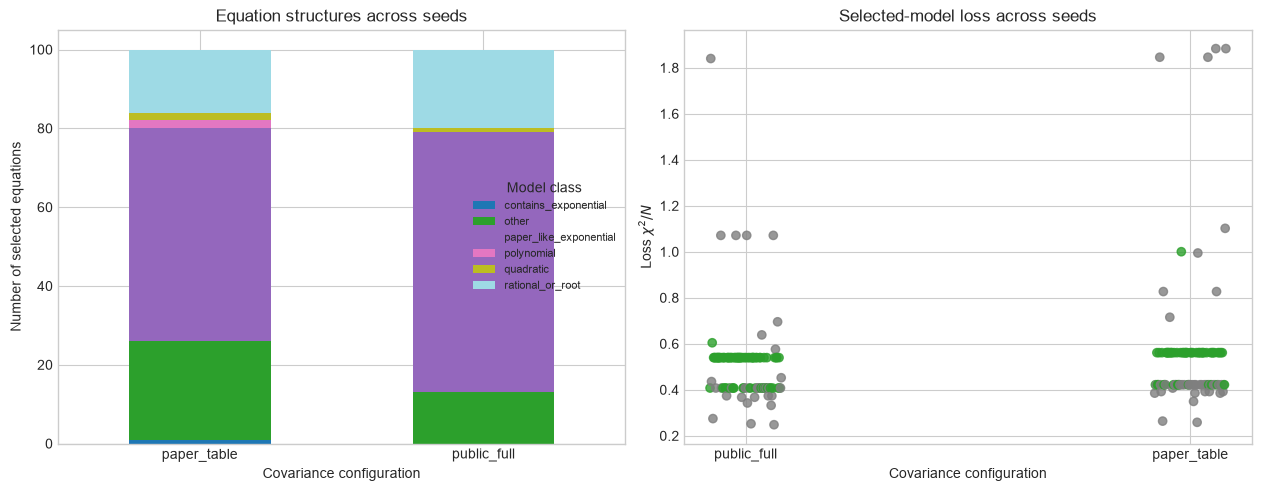

Saved figure: /Users/kemingliu/Desktop/Dark Energy/results/03_desi_pysr_seed_stability/targeted_maxsize7_100seeds_final_20260906/figures/seed_stability_summary.png


In [37]:
if classified_summary.empty:
    print("No results are available for plotting.")
else:
    from matplotlib.lines import Line2D

    covariance_names = list(COVARIANCE_CONFIGS)
    count_table = (
        structure_counts
        .pivot(index="covariance", columns="model_class", values="count")
        .fillna(0)
        .reindex(covariance_names)
    )

    fig, axes = plt.subplots(1, 2, figsize=(13.5, 6.2), constrained_layout=True)
    count_table.plot(kind="bar", stacked=True, ax=axes[0], colormap="tab20")
    axes[0].set(
        xlabel="Covariance configuration",
        ylabel="Number of selected equations",
        title="Equation structures across seeds",
    )
    axes[0].tick_params(axis="x", rotation=0)
    left_handles, left_labels = axes[0].get_legend_handles_labels()
    readable_labels = [label.replace("_", " ") for label in left_labels]
    axes[0].legend(
        left_handles,
        readable_labels,
        title="Model class",
        loc="upper center",
        bbox_to_anchor=(0.5, -0.18),
        ncol=2,
        fontsize=8,
        frameon=True,
    )

    for position, covariance_name in enumerate(covariance_names):
        subset = classified_summary.loc[
            classified_summary["covariance"] == covariance_name
        ]
        x_positions = np.full(len(subset), position, dtype=float)
        offsets = np.linspace(-0.08, 0.08, len(subset)) if len(subset) > 1 else 0.0
        colors = np.where(
            subset["model_class"] == "paper_like_exponential",
            "tab:green",
            "tab:gray",
        )
        axes[1].scatter(x_positions + offsets, subset["python_loss"], c=colors, alpha=0.8)
    axes[1].set_xticks(range(len(covariance_names)), covariance_names)
    axes[1].set(
        xlabel="Covariance configuration",
        ylabel=r"Loss $\chi^2/N$",
        title="Selected-model loss across seeds",
    )
    right_legend_handles = [
        Line2D(
            [0], [0], marker="o", linestyle="none", color="tab:green",
            label="Paper-like exponential", markersize=7,
        ),
        Line2D(
            [0], [0], marker="o", linestyle="none", color="tab:gray",
            label="Other selected structure", markersize=7,
        ),
    ]
    axes[1].legend(
        handles=right_legend_handles,
        loc="upper center",
        bbox_to_anchor=(0.5, -0.18),
        ncol=2,
        fontsize=9,
        frameon=True,
    )

    FIGURE_FILE = FIGURES_DIR / "seed_stability_summary.png"
    fig.savefig(FIGURE_FILE, dpi=180, bbox_inches="tight")
    plt.show()
    print(f"Saved figure: {FIGURE_FILE}")

## 10. Completion check and interpretation

Do not conclude that the paper has been robustly reproduced from one successful seed. The stability claim should be based on the complete multi-seed table, the exponential hit rate, and the variation of the fitted $A$ and $B$ parameters.

In [38]:
expected_pairs = {
    (covariance_name, seed)
    for covariance_name in COVARIANCE_CONFIGS
    for seed in TARGETED_SEEDS
}
completed_pairs = (
    set(zip(classified_summary["covariance"], classified_summary["seed"]))
    if not classified_summary.empty
    else set()
)
missing_pairs = sorted(expected_pairs - completed_pairs)

if missing_pairs:
    print(f"Experiment incomplete: {len(missing_pairs)} runs remain.")
    display(pd.DataFrame(missing_pairs, columns=["covariance", "seed"]))
else:
    print("Experiment complete: every covariance-seed pair has a saved result.")
    print("Use exponential_hit_rates.csv and classified_summary.csv in the research log.")

Experiment complete: every covariance-seed pair has a saved result.
Use exponential_hit_rates.csv and classified_summary.csv in the research log.
